# JobMatch — Analyse exploratoire
## 1. Introduction et objectifs
**Question du projet :** peut-on estimer le salaire d'une offre à partir du métier, de l'expérience et de la localisation ?
Cette EDA vérifie les données, décrit les salaires et étudie les associations utiles à la modélisation.
La recommandation d'offres reste un prolongement complémentaire. Aucun modèle n'est entraîné ici.

## 2. Présentation du dataset
Source annoncée : **Job Market Intelligence 2024 - Skills Global Dataset**, Kaggle.
Une ligne de `fact_job_postings.csv` représente une offre. `bridge_job_skills.csv` associe une offre à plusieurs compétences.
Les quatre tables de dimensions décrivent les compétences, entreprises, pays/régions et plateformes.
La méthode de collecte et la période salariale ne sont pas établies par les seuls CSV.

Les salaires du dataset sont initialement exprimés en dollars américains. Pour faciliter la lecture,
les résultats sont présentés en euros avec un taux indicatif fixe de 1 USD = 0,92 EUR.
Ce taux de présentation n'est ni un taux actuel ni un taux officiel. Les montants ne sont pas corrigés du coût de la vie.

## 3. Chargement des données
Choisir le Python de `.venv/Scripts/python.exe`, redémarrer le noyau puis exécuter toutes les cellules dans l'ordre.
Les CSV sources ne sont jamais modifiés ; les colonnes calculées sont ajoutées à une copie en mémoire.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import chi2_contingency
from IPython.display import display

project_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "data/raw/fact_job_postings.csv").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Ouvrez le notebook depuis JobMatch ou son dossier notebooks.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.analysis import (
    USD_TO_EUR, SKILL_FAMILIES, add_salary_columns, salary_summary,
    group_percentages, to_skill_families, skill_pairs, skill_prevalence,
    cramers_v, eta_squared,
)

def nombre_fr(value, decimals=2):
    return f"{value:,.{decimals}f}".replace(",", " ").replace(".", ",")

pd.options.display.float_format = nombre_fr
def afficher(obj):
    if isinstance(obj, pd.Series):
        obj = obj.to_frame()
    if not isinstance(obj, pd.DataFrame):
        return display(obj)
    formats = {}
    for column in obj.columns:
        if pd.api.types.is_integer_dtype(obj[column]):
            formats[column] = lambda x: nombre_fr(x, 0)
        elif pd.api.types.is_float_dtype(obj[column]):
            decimals = 6 if "p_value" in str(column) else 2
            formats[column] = lambda x, d=decimals: nombre_fr(x, d)
    view = obj.style.format(formats, na_rep="—")
    if "count" in obj.index:
        numeric = obj.select_dtypes(include="number").columns
        view = view.format(lambda x: nombre_fr(x, 0), subset=pd.IndexSlice[["count"], numeric])
    display(view)

data_dir = project_root / "data/raw"
tables = {name: pd.read_csv(data_dir / filename) for name, filename in {
    "offres": "fact_job_postings.csv", "liens_competences": "bridge_job_skills.csv",
    "competences": "dim_skill.csv", "entreprises": "dim_company.csv",
    "pays": "dim_country.csv", "plateformes": "dim_platform.csv"}.items()}
offres_brutes = tables["offres"]
offres = add_salary_columns(offres_brutes)
competences_offres = tables["liens_competences"]
liste_competences = tables["competences"]
familles_offres = to_skill_families(competences_offres)
print("Python utilisé :", sys.executable)
print(f"Taux indicatif de présentation : 1 USD = {nombre_fr(USD_TO_EUR)} EUR")

Python utilisé : C:\Users\www\JobMatch\.venv\Scripts\python.exe
Taux indicatif de présentation : 1 USD = 0,92 EUR


## 4. Compréhension des tables et de leurs relations
La clé des offres est `job_id`. La table de liaison est au niveau **offre-compétence** :
ses lignes ne doivent pas servir à compter les offres ni à calculer les statistiques salariales.
Les dimensions fournissent des libellés de référence.

In [2]:
# Cette cellule peut aussi être lancée seule après un redémarrage du noyau.
_variables_requises = ("afficher", "pd", "tables", "offres_brutes", "offres")
if not all(nom in globals() for nom in _variables_requises):
    import json as _json_notebook
    from pathlib import Path as _CheminNotebook

    _racine = next(
        (p for p in [_CheminNotebook.cwd(), *_CheminNotebook.cwd().parents]
         if (p / "notebooks/01_EDA.ipynb").is_file()),
        None,
    )
    if _racine is None:
        raise FileNotFoundError("Ouvrez le dossier JobMatch dans VS Code avant d'exécuter cette cellule.")
    _notebook = _json_notebook.loads(
        (_racine / "notebooks/01_EDA.ipynb").read_text(encoding="utf-8")
    )
    _chargement = next(c for c in _notebook["cells"] if c.get("id") == "eda-03")
    print("Initialisation des fonctions d'affichage et chargement des six tables…")
    get_ipython().run_cell("".join(_chargement["source"]))
    if not all(nom in globals() for nom in _variables_requises):
        raise RuntimeError(
            "Le chargement n'a pas abouti. Consultez la première erreur affichée ci-dessus "
            "et sélectionnez le Python .venv/Scripts/python.exe."
        )

afficher(pd.DataFrame([{"table": name, "lignes": len(table), "colonnes": table.shape[1]}
                      for name, table in tables.items()]).set_index("table"))
afficher(offres_brutes.dtypes.astype(str).rename("type_source"))
# Les exemples de montants sont présentés en EUR ; les colonnes sources restent disponibles.
exemple = ["job_id", "job_title", "country", "experience_level", "remote_option",
           "salary_min_eur", "salary_max_eur", "salary_mid_eur", "applicants_estimate"]
afficher(offres[exemple].head())
afficher(offres[exemple].sample(5, random_state=42))
offres_brutes.info()

,lignes,colonnes
table,,
offres,55 000,13
liens_competences,247 398,2
competences,26,1
entreprises,20,1
pays,13,2
plateformes,6,1


,type_source
job_id,str
job_title,str
company,str
country,str
region,str
platform,str
experience_level,str
employment_type,str
salary_min_usd,int64
salary_max_usd,int64


,job_id,job_title,country,experience_level,remote_option,salary_min_eur,salary_max_eur,salary_mid_eur,applicants_estimate
0,JOB-1,Senior Data Engineer,Spain,Lead,Hybrid,"150 632,52","157 335,64","153 984,08",472
1,JOB-2,Data Engineer,India,Mid,Hybrid,"133 595,96","141 185,04","137 390,50",500
2,JOB-3,Business Intelligence Analyst,Netherlands,Entry,Onsite,"80 229,52","112 231,72","96 230,62",34
3,JOB-4,Data Scientist,Netherlands,Lead,Remote,"96 040,64","120 475,84","108 258,24",26
4,JOB-5,AI Engineer,Germany,Mid,Hybrid,"149 745,64","171 240,52","160 493,08",303


,job_id,job_title,country,experience_level,remote_option,salary_min_eur,salary_max_eur,salary_mid_eur,applicants_estimate
34191,JOB-34192,Senior Data Scientist,UAE,Lead,Remote,"103 140,28","127 149,52","115 144,90",362
23679,JOB-23680,Business Intelligence Analyst,Netherlands,Entry,Hybrid,"80 483,44","90 930,04","85 706,74",480
44684,JOB-44685,Data Scientist,United States,Senior,Remote,"112 228,96","120 945,96","116 587,46",405
11335,JOB-11336,Data Scientist,Spain,Senior,Onsite,"121 068,32","148 600,24","134 834,28",302
22691,JOB-22692,Data Engineer,Singapore,Mid,Remote,"164 043,36","175 292,20","169 667,78",113


<class 'pandas.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               55000 non-null  str  
 1   job_title            55000 non-null  str  
 2   company              55000 non-null  str  
 3   country              55000 non-null  str  
 4   region               55000 non-null  str  
 5   platform             55000 non-null  str  
 6   experience_level     55000 non-null  str  
 7   employment_type      55000 non-null  str  
 8   salary_min_usd       55000 non-null  int64
 9   salary_max_usd       55000 non-null  int64
 10  remote_option        55000 non-null  str  
 11  posting_date         55000 non-null  str  
 12  applicants_estimate  55000 non-null  int64
dtypes: int64(3), str(10)
memory usage: 9.8 MB


## 5. Vérification de la qualité des données

In [3]:
controle = pd.Series({
    "offres": len(offres_brutes),
    "valeurs_manquantes": int(offres_brutes.isna().sum().sum()),
    "lignes_dupliquees": int(offres_brutes.duplicated().sum()),
    "job_id_dupliques": int(offres_brutes.job_id.duplicated().sum()),
    "liens_competences_dupliques": int(competences_offres.duplicated(["job_id", "skill"]).sum()),
    "bornes_salariales_invalides": int((~np.isfinite(offres_brutes.salary_min_usd)
        | ~np.isfinite(offres_brutes.salary_max_usd)
        | offres_brutes.salary_min_usd.le(0)
        | offres_brutes.salary_max_usd.lt(offres_brutes.salary_min_usd)).sum()),
    "liens_sans_offre": len(set(competences_offres.job_id) - set(offres.job_id)),
    "offres_sans_competence": len(set(offres.job_id) - set(competences_offres.job_id)),
    "competences_hors_reference": len(set(competences_offres.skill) - set(liste_competences.skill)),
    "entreprises_hors_reference": len(set(offres.company) - set(tables["entreprises"].company)),
    "pays_hors_reference": len(set(offres.country) - set(tables["pays"].country)),
    "plateformes_hors_reference": len(set(offres.platform) - set(tables["plateformes"].platform)),
}, name="nombre")
afficher(controle)
afficher(offres_brutes.isna().sum().rename("valeurs_manquantes"))
for column in ["job_title", "experience_level", "employment_type", "remote_option"]:
    afficher(offres[column].value_counts(dropna=False).rename("nombre_offres"))
afficher(offres.posting_date.value_counts().head(10).rename("nombre_offres"))


# Vérifications pédagogiques : clés, bornes, conversion et cardinalité de jointure.
assert offres_brutes.job_id.notna().all() and offres_brutes.job_id.is_unique
assert controle[["bornes_salariales_invalides", "liens_sans_offre", "competences_hors_reference"]].eq(0).all()
np.testing.assert_allclose(
    offres[["salary_min_eur", "salary_max_eur", "salary_mid_eur"]].to_numpy(),
    offres[["salary_min_usd", "salary_max_usd", "salary_mid_usd"]].to_numpy() * USD_TO_EUR,
)
jointure_controle = offres[["job_id"]].merge(
    competences_offres[["job_id", "skill"]], on="job_id", validate="one_to_many")
assert len(jointure_controle) == len(competences_offres)
print("Contrôles validés : IDs uniques, bornes cohérentes, conversion EUR et jointure sans multiplication inattendue.")

,nombre
offres,55 000
valeurs_manquantes,0
lignes_dupliquees,0
job_id_dupliques,0
liens_competences_dupliques,0
bornes_salariales_invalides,0
liens_sans_offre,0
offres_sans_competence,0
competences_hors_reference,0
entreprises_hors_reference,0


,valeurs_manquantes
job_id,0
job_title,0
company,0
country,0
region,0
platform,0
experience_level,0
employment_type,0
salary_min_usd,0
salary_max_usd,0


,nombre_offres
job_title,
Business Intelligence Analyst,5 651
AI Engineer,5 595
Senior Data Engineer,5 584
Senior Data Scientist,5 572
Analytics Engineer,5 534
Data Analyst,5 506
Data Engineer,5 420
Data Scientist,5 408
Machine Learning Engineer,5 382


,nombre_offres
experience_level,
Entry,13 877
Senior,13 772
Lead,13 702
Mid,13 649


,nombre_offres
employment_type,
Full-time,18 470
Contract,18 298
Part-time,18 232


,nombre_offres
remote_option,
Onsite,18 587
Hybrid,18 226
Remote,18 187


,nombre_offres
posting_date,
52:59.5,11 580
52:59.6,11 156
52:59.7,11 136
52:59.8,8 393
52:59.3,7 206
52:59.4,5 529


Contrôles validés : IDs uniques, bornes cohérentes, conversion EUR et jointure sans multiplication inattendue.


Les contrôles doivent être lus avec leurs résultats : l'absence de valeur manquante ne garantit pas la représentativité.
Les valeurs de `posting_date` ressemblent à des fragments d'heure, pas à des dates calendaires complètes.
Aucune tendance temporelle ni validation chronologique ne sera construite à partir de cette colonne.

## 6. Analyse descriptive des métiers

,nombre_offres,part_offres_pct
metier,,
Business Intelligence Analyst,5 651,"10,27"
AI Engineer,5 595,"10,17"
Senior Data Engineer,5 584,"10,15"
Senior Data Scientist,5 572,"10,13"
Analytics Engineer,5 534,"10,06"
Data Analyst,5 506,"10,01"
Data Engineer,5 420,"9,85"
Data Scientist,5 408,"9,83"
Machine Learning Engineer,5 382,"9,79"


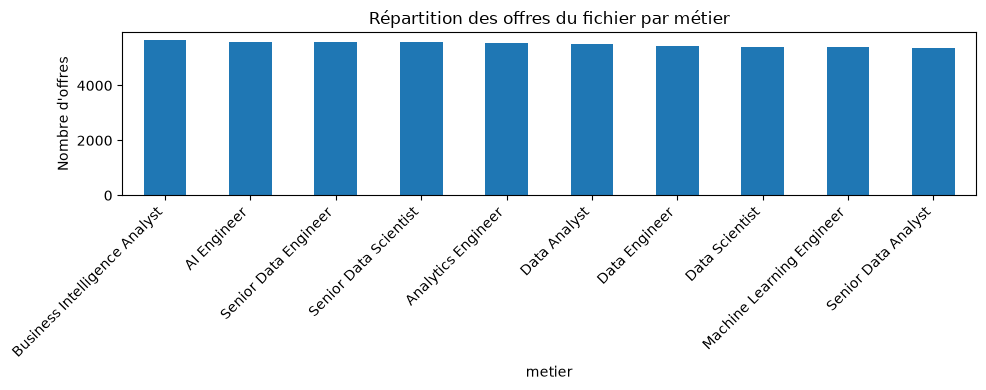

In [4]:
metiers = offres.job_title.value_counts().rename_axis("metier").to_frame("nombre_offres")
metiers["part_offres_pct"] = metiers.nombre_offres / offres.job_id.nunique() * 100
afficher(metiers)
metiers.nombre_offres.plot.bar(figsize=(10, 4))
plt.title("Répartition des offres du fichier par métier")
plt.ylabel("Nombre d'offres")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Le fichier contient dix intitulés aux effectifs proches. Cela décrit l'échantillon, sans classer la demande réelle du marché.
Data Analyst est un cas d'étude adapté à l'objectif du groupe, avec 5 506 offres.
**Business Analyst est absent** ; Business Intelligence Analyst est un intitulé distinct et ne permet pas de remplacer cette comparaison.

## 7. Analyse des salaires
Le milieu d'une fourchette vaut `(minimum + maximum) / 2` ; ce calcul n'est pas une médiane.
La médiane est ensuite calculée entre les milieux des offres d'un groupe. Il s'agit d'un indicateur de rémunération affichée,
pas d'un salaire effectivement versé. La période de rémunération doit être confirmée avant de parler de salaire annuel.

Les tableaux donnent les effectifs, minimum, moyenne, Q1, médiane, Q3, maximum et écart-type en **euros**.

### 7.1. Statistiques descriptives en euros

In [5]:
afficher(offres[["salary_min_eur", "salary_max_eur", "salary_mid_eur"]].describe())

,salary_min_eur,salary_max_eur,salary_mid_eur
count,55 000,55 000,55 000
mean,"103 029,33","121 434,81","112 232,07"
std,"33 819,74","34 713,73","34 037,56"
min,"41 400,92","46 229,08","43 838,46"
25%,"75 190,68","93 141,95","84 149,29"
50%,"103 996,80","122 266,16","113 166,21"
75%,"130 385,62","148 906,37","139 543,42"
max,"165 595,40","197 512,04","181 443,78"


### 7.2. Comparaisons par expérience, métier et pays

In [6]:
bilans_salaires = {}
for dimension in ["experience_level", "job_title", "country"]:
    bilans_salaires[dimension] = salary_summary(offres, dimension)
    print("Milieu des fourchettes — statistiques en € —", dimension)
    afficher(bilans_salaires[dimension].sort_values("mediane_eur"))

salaires_croises = salary_summary(offres, ["job_title", "experience_level", "country"])
salaires_retenus = salaires_croises.loc[salaires_croises.nombre_offres.ge(30)]
print(f"Groupes croisés retenus au seuil descriptif de 30 offres : {len(salaires_retenus)} / {len(salaires_croises)}")
print("Extrait des groupes croisés ; le tableau complet reste dans salaires_retenus.")
afficher(salaires_retenus.head(12))
print("Médianes en € à métier comparable :")
afficher(offres.pivot_table(index="job_title", columns="experience_level",
                          values="salary_mid_eur", aggfunc="median"))

Milieu des fourchettes — statistiques en € — experience_level


,nombre_offres,minimum_eur,moyenne_eur,q1_eur,mediane_eur,q3_eur,maximum_eur,ecart_type_eur
experience_level,,,,,,,,
Senior,13 772,"43 892,74","112 167,97","84 018,89","112 817,07","139 670,72","181 058,76","34 093,85"
Entry,13 877,"43 945,18","112 167,18","84 466,12","112 998,08","139 375,86","181 061,98","33 748,33"
Lead,13 702,"43 950,70","112 185,91","84 016,59","113 468,89","139 684,64","180 870,62","34 154,70"
Mid,13 649,"43 838,46","112 409,07","84 136,76","113 471,42","139 486,26","181 443,78","34 158,64"


Milieu des fourchettes — statistiques en € — job_title


,nombre_offres,minimum_eur,moyenne_eur,q1_eur,mediane_eur,q3_eur,maximum_eur,ecart_type_eur
job_title,,,,,,,,
Senior Data Analyst,5 348,"43 950,70","71 268,70","60 955,18","71 092,54","81 444,04","98 527,40","12 530,47"
Data Analyst,5 506,"43 892,74","71 259,69","60 766,92","71 105,65","81 745,45","98 098,22","12 626,69"
Business Intelligence Analyst,5 651,"43 838,46","71 409,41","61 210,36","71 271,94","81 533,85","98 605,14","12 523,75"
Data Scientist,5 408,"76 627,26","114 817,15","98 883,79","114 333,92","130 619,53","153 769,72","18 966,40"
Senior Data Scientist,5 572,"76 610,70","115 319,49","98 848,37","115 325,91","132 052,89","153 577,44","19 130,69"
Senior Data Engineer,5 584,"90 372,98","135 343,63","115 903,79","134 929,96","154 869,12","180 486,98","22 651,06"
Machine Learning Engineer,5 382,"90 156,78","135 482,73","116 009,93","135 610,30","155 107,86","181 384,90","22 968,91"
Analytics Engineer,5 534,"90 456,70","135 622,61","116 668,99","135 777,05","154 680,29","180 868,78","22 671,79"
Data Engineer,5 420,"90 017,40","135 718,43","116 342,74","135 950,01","155 092,91","181 443,78","22 931,52"


Milieu des fourchettes — statistiques en € — country


,nombre_offres,minimum_eur,moyenne_eur,q1_eur,mediane_eur,q3_eur,maximum_eur,ecart_type_eur
country,,,,,,,,
Australia,4 261,"44 111,70","111 822,03","83 123,84","111 885,34","139 975,70","180 939,62","34 284,85"
Brazil,4 151,"44 056,96","111 935,07","83 883,76","112 246,90","139 370,57","181 058,76","34 240,70"
Singapore,4 211,"43 838,46","111 851,74","84 394,36","112 255,64","139 592,75","181 190,78","33 863,87"
Germany,4 232,"44 710,62","111 754,52","83 048,17","112 368,57","139 697,98","180 486,98","34 272,52"
France,4 398,"44 597,92","112 022,04","83 618,23","112 498,29","139 158,51","181 384,90","34 106,88"
Ireland,4 287,"44 526,16","111 768,39","83 464,93","112 606,16","138 666,77","180 931,34","33 906,40"
Spain,4 145,"43 945,18","111 739,48","83 590,28","113 142,06","139 073,64","180 363,70","34 112,99"
United Kingdom,4 249,"45 235,48","112 513,40","85 183,26","113 339,40","139 143,56","181 443,78","33 864,04"
Netherlands,4 218,"44 080,42","112 521,08","84 245,78","113 624,14","140 116,69","181 326,94","34 034,03"


Groupes croisés retenus au seuil descriptif de 30 offres : 520 / 520
Extrait des groupes croisés ; le tableau complet reste dans salaires_retenus.


Médianes en € à métier comparable :


experience_level,Entry,Lead,Mid,Senior
job_title,,,,
AI Engineer,"136 143,44","136 606,20","134 864,18","136 133,78"
Analytics Engineer,"133 601,25","135 503,58","136 975,35","136 498,10"
Business Intelligence Analyst,"71 178,33","69 971,52","72 057,62","71 685,25"
Data Analyst,"71 574,62","70 336,07","71 250,32","71 411,55"
Data Engineer,"134 971,82","135 964,50","136 350,44","136 530,07"
Data Scientist,"115 119,14","112 993,71","113 969,14","115 549,24"
Machine Learning Engineer,"135 644,80","136 068,92","136 770,42","134 548,39"
Senior Data Analyst,"71 218,58","71 198,80","70 672,10","71 410,40"
Senior Data Engineer,"133 303,86","134 475,02","136 355,50","136 208,30"


### 7.3. Graphiques salariaux en euros

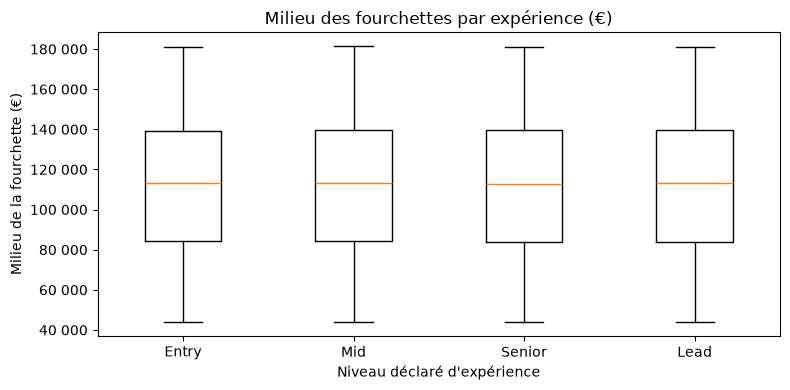

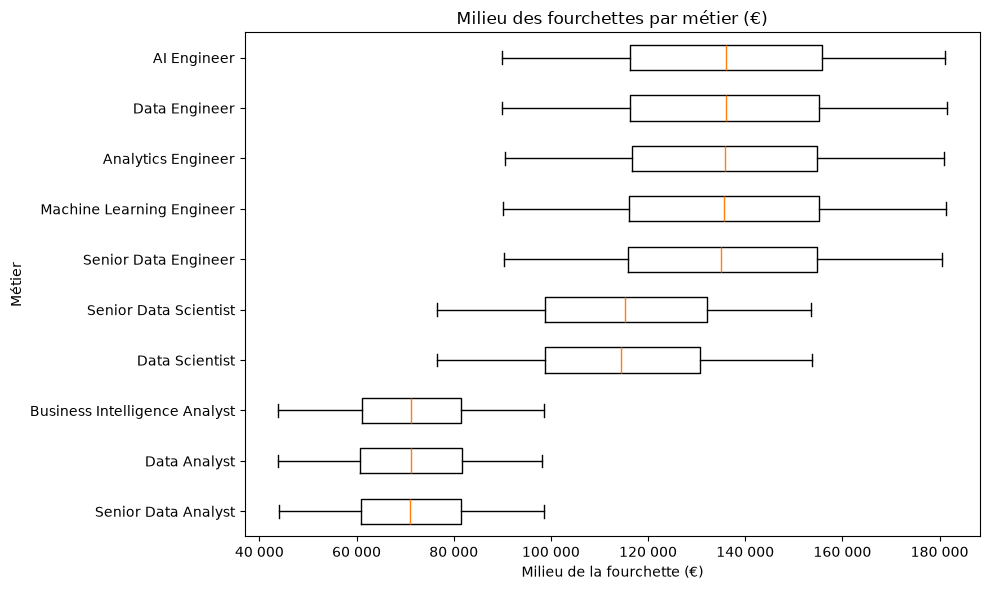

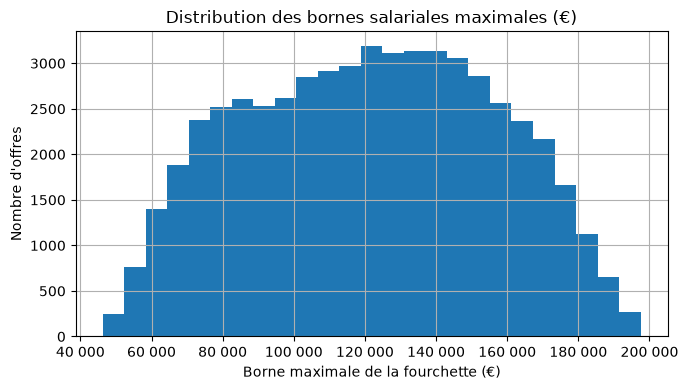

In [7]:
from inspect import signature
from matplotlib.ticker import FuncFormatter
formater_euros = FuncFormatter(lambda value, position: nombre_fr(value, 0))
options_horizontal = ({"orientation": "horizontal"} if "orientation" in signature(plt.Axes.boxplot).parameters
                      else {"vert": False})

niveaux = ["Entry", "Mid", "Senior", "Lead"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([offres.loc[offres.experience_level.eq(n), "salary_mid_eur"] for n in niveaux])
ax.set_xticks(range(1, len(niveaux) + 1), niveaux)
ax.set_title("Milieu des fourchettes par expérience (€)")
ax.set_xlabel("Niveau déclaré d'expérience")
ax.set_ylabel("Milieu de la fourchette (€)")
ax.yaxis.set_major_formatter(formater_euros)
plt.tight_layout()
plt.show()

ordre = offres.groupby("job_title").salary_mid_eur.median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot([offres.loc[offres.job_title.eq(m), "salary_mid_eur"] for m in ordre], **options_horizontal)
ax.set_yticks(range(1, len(ordre) + 1), ordre)
ax.set_title("Milieu des fourchettes par métier (€)")
ax.set_xlabel("Milieu de la fourchette (€)")
ax.set_ylabel("Métier")
ax.xaxis.set_major_formatter(formater_euros)
plt.tight_layout()
plt.show()

offres.salary_max_eur.hist(bins=25, figsize=(7, 4))
plt.title("Distribution des bornes salariales maximales (€)")
plt.xlabel("Borne maximale de la fourchette (€)")
plt.ylabel("Nombre d'offres")
plt.gca().xaxis.set_major_formatter(formater_euros)
plt.tight_layout()
plt.show()

Les médianes des milieux se situent autour de 71 000 € pour les métiers Analyst, 114 000–115 000 € pour Data Scientist,
et 135 000–136 000 € pour les métiers Engineer. Les différences observées selon l'expérience et le pays sont plus faibles.
La comparaison à métier comparable complète les résultats tous métiers confondus.

Le milieu d'une fourchette ne suffit pas à expliquer cette faible variation : elle doit être constatée dans les données,
sans lui attribuer une cause non démontrée. Une moyenne proche de la médiane ne prouve ni la symétrie ni l'absence de valeurs extrêmes.

## 8. Analyse de l'expérience

In [8]:
experience = offres.experience_level.value_counts().rename_axis("niveau").to_frame("nombre_offres")
experience["part_offres_pct"] = experience.nombre_offres / len(offres) * 100
afficher(experience)
afficher(group_percentages(offres, ["job_title"], "experience_level").set_index(["job_title", "experience_level"]))

,nombre_offres,part_offres_pct
niveau,,
Entry,13 877,"25,23"
Senior,13 772,"25,04"
Lead,13 702,"24,91"
Mid,13 649,"24,82"


Les quatre niveaux représentent chacun environ un quart des offres. Entry est utilisé comme approximation de junior.
Le niveau provient de `experience_level` : il n'est pas déduit de la présence du mot « Senior » dans le titre.
Les proportions sont calculées dans chaque métier pour tenir compte de ses effectifs.

## 9. Analyse des modes de travail

Mode de travail selon l'expérience : nombre d'offres (% du niveau)


,Hybrid,Onsite,Remote,effectif_groupe
experience_level,,,,
Entry,"4 610 (33,2 %)","4 690 (33,8 %)","4 577 (33,0 %)",13 877
Lead,"4 568 (33,3 %)","4 627 (33,8 %)","4 507 (32,9 %)",13 702
Mid,"4 507 (33,0 %)","4 628 (33,9 %)","4 514 (33,1 %)",13 649
Senior,"4 541 (33,0 %)","4 642 (33,7 %)","4 589 (33,3 %)",13 772


Mode de travail selon le métier : nombre d'offres (% du métier)


,Hybrid,Onsite,Remote,effectif_groupe
job_title,,,,
AI Engineer,"1 822 (32,6 %)","1 839 (32,9 %)","1 934 (34,6 %)",5 595
Analytics Engineer,"1 877 (33,9 %)","1 840 (33,2 %)","1 817 (32,8 %)",5 534
Business Intelligence Analyst,"1 844 (32,6 %)","1 907 (33,7 %)","1 900 (33,6 %)",5 651
Data Analyst,"1 821 (33,1 %)","1 939 (35,2 %)","1 746 (31,7 %)",5 506
Data Engineer,"1 822 (33,6 %)","1 866 (34,4 %)","1 732 (32,0 %)",5 420
Data Scientist,"1 835 (33,9 %)","1 774 (32,8 %)","1 799 (33,3 %)",5 408
Machine Learning Engineer,"1 712 (31,8 %)","1 816 (33,7 %)","1 854 (34,4 %)",5 382
Senior Data Analyst,"1 815 (33,9 %)","1 816 (34,0 %)","1 717 (32,1 %)",5 348
Senior Data Engineer,"1 847 (33,1 %)","1 901 (34,0 %)","1 836 (32,9 %)",5 584


Mode de travail selon le métier et l'expérience : nombre d'offres (% du groupe)


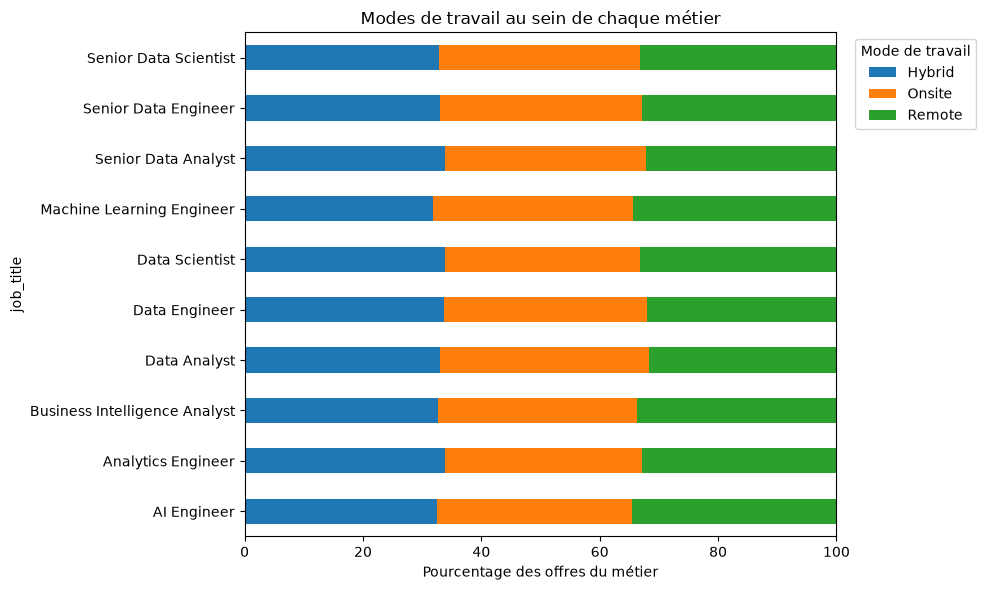

,min,max,ecart_points
remote_option,,,
Hybrid,"30,52","35,48","4,97"
Onsite,"31,14","36,48","5,34"
Remote,"30,72","36,87","6,15"


In [9]:
modes_metier = group_percentages(offres, ["job_title"], "remote_option")
modes_croises = group_percentages(offres, ["job_title", "experience_level"], "remote_option")

def tableau_effectifs_pourcentages(resultat, groupes):
    """Une case = nombre d'offres (pourcentage du groupe) ; effectif du groupe en dernière colonne."""
    resultat = resultat.assign(case=resultat.apply(
        lambda r: f"{r.nombre_offres:,} ({r.pourcentage:.1f} %)".replace(",", " ").replace(".", ","), axis=1))
    tableau = resultat.pivot_table(index=groupes, columns="remote_option", values="case", aggfunc="first")
    tableau["effectif_groupe"] = resultat.groupby(groupes).effectif_groupe.first()
    tableau.columns.name = None
    return tableau

# Mode de travail selon l'expérience
modes_experience = group_percentages(offres, ["experience_level"], "remote_option")
print("Mode de travail selon l'expérience : nombre d'offres (% du niveau)")
afficher(tableau_effectifs_pourcentages(modes_experience, ["experience_level"]))

# Mode de travail selon le métier
print("Mode de travail selon le métier : nombre d'offres (% du métier)")
afficher(tableau_effectifs_pourcentages(modes_metier, ["job_title"]))

# Mode de travail selon le métier et l'expérience
print("Mode de travail selon le métier et l'expérience : nombre d'offres (% du groupe)")
with pd.option_context("display.max_rows", 60):
    afficher(tableau_effectifs_pourcentages(modes_croises, ["job_title", "experience_level"]))

graphique_modes = modes_metier.pivot(index="job_title", columns="remote_option", values="pourcentage").fillna(0)
graphique_modes.plot.barh(stacked=True, figsize=(10, 6))
plt.title("Modes de travail au sein de chaque métier")
plt.xlabel("Pourcentage des offres du métier")
plt.xlim(0, 100)
plt.legend(title="Mode de travail", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

ecarts_modes = modes_croises.groupby("remote_option").pourcentage.agg(["min", "max"])
ecarts_modes["ecart_points"] = ecarts_modes["max"] - ecarts_modes["min"]
afficher(ecarts_modes.round(2))

Les tableaux combinent effectif et pourcentage du groupe. Les trois modes représentent environ un tiers des offres
dans chaque groupe métier × expérience. La significativité et la taille des associations sont examinées en section 14.

## 10. Analyse des compétences

,nombre_offres,part_offres_pct
skill,,
Kafka,9 665,"17,57"
Tableau,9 660,"17,56"
Data Visualization,9 655,"17,55"
NLP,9 616,"17,48"
SQL,9 602,"17,46"
ETL,9 597,"17,45"
BigQuery,9 562,"17,39"
NumPy,9 558,"17,38"
Pandas,9 544,"17,35"


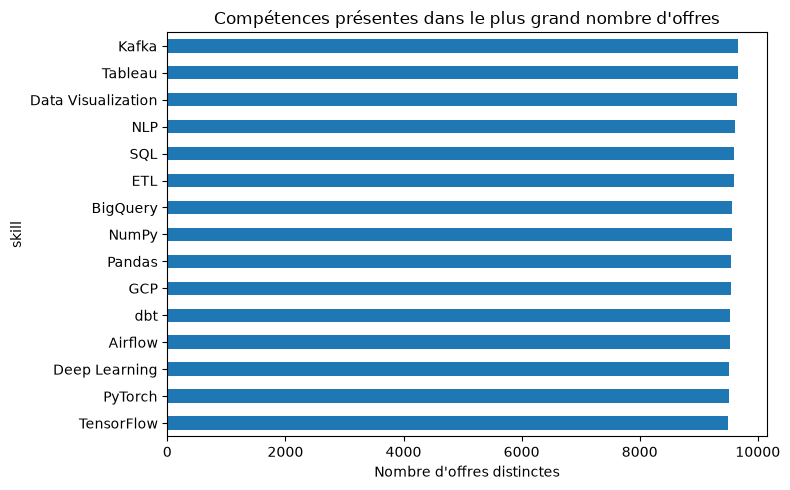

In [10]:
liens_uniques = competences_offres[["job_id", "skill"]].drop_duplicates()
effectifs_competences = liens_uniques.groupby("skill").job_id.nunique().sort_values(ascending=False)
classement_competences = effectifs_competences.rename("nombre_offres").to_frame()
classement_competences["part_offres_pct"] = classement_competences.nombre_offres / offres.job_id.nunique() * 100
afficher(classement_competences.head(15))
effectifs_competences.head(15).sort_values().plot.barh(figsize=(8, 5))
plt.title("Compétences présentes dans le plus grand nombre d'offres")
plt.xlabel("Nombre d'offres distinctes")
plt.tight_layout()
plt.show()

### Familles de compétences

Plusieurs des 26 compétences du fichier sont **proches ou concurrentes**. Par exemple, Tableau et Power BI sont deux logiciels qui font la même chose (des tableaux de bord), et une entreprise utilise en général l'un **ou** l'autre. Les compter séparément dans un classement disperse l'information. Je les regroupe donc en **9 familles**, selon l'usage de chaque outil :

| Famille | Compétences | À quoi elles servent |
|---|---|---|
| SQL | SQL | interroger une base de données |
| Entrepôts cloud | BigQuery, Redshift, Snowflake | stocker et interroger de gros volumes dans le cloud |
| Cloud | AWS, GCP, Azure | plateformes cloud concurrentes |
| Visualisation / BI | Tableau, Power BI, Data Visualization, Excel | présenter les données (graphiques, tableaux de bord) |
| Pipelines / Data Engineering | Airflow, dbt, ETL, Data Engineering | transporter, transformer et automatiser les flux de données |
| Big Data / streaming | Spark, Kafka | traiter des données massives ou en temps réel |
| Python et librairies | Python, Pandas, NumPy | programmer et manipuler des données |
| Machine Learning / IA | Machine Learning, Deep Learning, TensorFlow, PyTorch, NLP | construire des modèles prédictifs |
| Statistiques | Statistics | méthodes statistiques |

Ce regroupement est un **choix de notre part** : il repose sur l'usage des outils, pas sur une information du fichier. Une offre qui demande à la fois Tableau et Power BI ne compte qu'**une fois** dans la famille Visualisation / BI.

Pour les paires de familles, chaque offre est comptée au maximum une fois. Le support est le pourcentage de toutes les offres demandant les deux familles. Le lift compare cette fréquence à celle attendue si les familles étaient indépendantes : supérieur à 1, elles sont plus souvent demandées ensemble ; inférieur à 1, elles le sont moins souvent.



Le classement par familles est complémentaire du classement par outil. Le nombre d'outils par famille est affiché :
une famille plus large a davantage de chances d'apparaître. Le support est la part de toutes les offres demandant les deux familles.
Le lift compare ce support à celui attendu sous indépendance ; un lift de 1 correspond à cette référence.

,nombre_offres,pct_offres,nombre_competences,competences
famille,,,,
Machine Learning / IA,34 916,"63,50",5,"Machine Learning, Deep Learning, TensorFlow, PyTorch, NLP"
Visualisation / BI,30 252,"55,00",4,"Tableau, Power BI, Data Visualization, Excel"
Pipelines / Data Engineering,30 201,"54,90",4,"Airflow, dbt, ETL, Data Engineering"
Cloud,24 460,"44,50",3,"AWS, GCP, Azure"
Entrepôts cloud,24 382,"44,30",3,"BigQuery, Redshift, Snowflake"
Python et librairies,24 252,"44,10",3,"Python, Pandas, NumPy"
Big Data / streaming,17 698,"32,20",2,"Spark, Kafka"
SQL,9 602,"17,50",1,SQL
Statistiques,9 446,"17,20",1,Statistics


,competence_1,competence_2,nombre_offres,support_pct,lift
rang,,,,,
1,Machine Learning / IA,Visualisation / BI,17 920,"32,58","0,93"
2,Machine Learning / IA,Pipelines / Data Engineering,17 893,"32,53","0,93"
3,Pipelines / Data Engineering,Visualisation / BI,15 523,"28,22","0,93"
4,Cloud,Machine Learning / IA,14 421,"26,22","0,93"
5,Machine Learning / IA,Python et librairies,14 363,"26,11","0,93"
6,Entrepôts cloud,Machine Learning / IA,14 354,"26,10","0,93"
7,Cloud,Pipelines / Data Engineering,12 447,"22,63","0,93"
8,Entrepôts cloud,Pipelines / Data Engineering,12 404,"22,55","0,93"
9,Cloud,Visualisation / BI,12 369,"22,49","0,92"


Lift des paires de familles : de 0.864 à 0.934


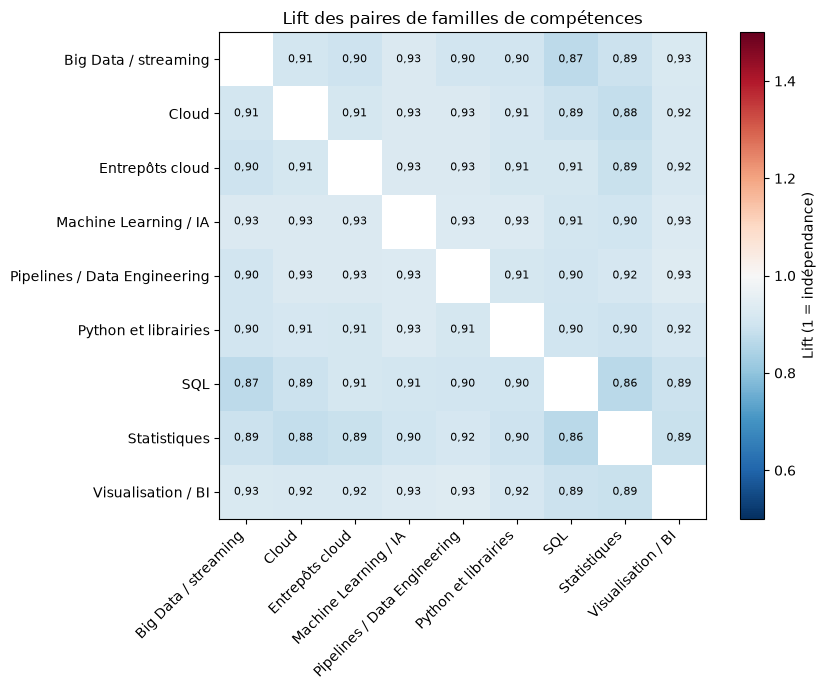

In [11]:
composition = pd.Series(SKILL_FAMILIES).rename_axis("competence").reset_index(name="famille").groupby("famille").competence.agg(", ".join)

frequence_familles = familles_offres.groupby("skill").job_id.nunique().rename("nombre_offres").to_frame()
frequence_familles["pct_offres"] = frequence_familles.nombre_offres / offres.job_id.nunique() * 100
frequence_familles["nombre_competences"] = pd.Series(SKILL_FAMILIES).value_counts()
frequence_familles["competences"] = composition
frequence_familles.index.name = "famille"
afficher(frequence_familles.sort_values("nombre_offres", ascending=False).round(1))

# Paires de familles : support et lift
paires_familles = skill_pairs(offres, familles_offres).reset_index(drop=True)
paires_familles.index = pd.RangeIndex(1, len(paires_familles) + 1, name="rang")
afficher(paires_familles.head(10).round(3))
print(f"Lift des paires de familles : de {paires_familles.lift.min():.3f} à {paires_familles.lift.max():.3f}")

# Heatmap du lift : blanc = 1 (hasard), rouge = plus souvent ensemble, bleu = moins souvent
noms_familles = sorted(frequence_familles.index)
matrice_lift = paires_familles.pivot(index="competence_1", columns="competence_2", values="lift")
matrice_lift = matrice_lift.reindex(index=noms_familles, columns=noms_familles)
matrice_lift = matrice_lift.combine_first(matrice_lift.T)
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(matrice_lift.to_numpy(), cmap="RdBu_r", norm=TwoSlopeNorm(vmin=0.5, vcenter=1, vmax=1.5))
ax.set_xticks(range(len(noms_familles)), noms_familles, rotation=45, ha="right")
ax.set_yticks(range(len(noms_familles)), noms_familles)
for (ligne, colonne), valeur in np.ndenumerate(matrice_lift.to_numpy()):
    if not np.isnan(valeur):
        ax.text(colonne, ligne, nombre_fr(valeur), ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Lift (1 = indépendance)")
ax.set_title("Lift des paires de familles de compétences")
plt.tight_layout()
plt.show()

Les lifts des paires de familles restent inférieurs à 1 dans ce fichier (environ 0,86–0,93).
Ces paires ne sont donc pas surreprésentées par rapport à la référence d'indépendance.
Cela ne prouve ni une absence générale d'association ni une attribution aléatoire des compétences.
La composition des familles et le nombre limité de compétences par offre doivent être pris en compte.

## 11. Comparaison des compétences selon les métiers
Le dénominateur est le nombre d'offres du métier, pas le nombre de liens de compétences.
Une offre peut appartenir à plusieurs familles : une ligne de pourcentages peut dépasser 100 %.

skill,Big Data / streaming,Cloud,Entrepôts cloud,Machine Learning / IA,Pipelines / Data Engineering,Python et librairies,SQL,Statistiques,Visualisation / BI
job_title,,,,,,,,,
AI Engineer,"32,20","46,00","42,90","63,70","55,20","43,60","18,10","17,40","55,90"
Analytics Engineer,"32,30","44,20","44,60","63,20","53,80","44,70","17,50","17,00","54,20"
Business Intelligence Analyst,"32,20","43,60","44,20","63,70","55,40","43,80","16,90","16,70","55,20"
Data Analyst,"33,00","44,00","44,60","63,00","55,90","43,20","17,80","17,30","54,40"
Data Engineer,"32,40","45,10","44,60","63,20","53,60","44,20","17,80","17,10","55,60"
Data Scientist,"31,00","44,60","44,40","64,40","54,10","43,50","18,50","17,60","55,40"
Machine Learning Engineer,"32,30","45,20","44,00","63,70","55,20","44,60","16,50","16,70","54,90"
Senior Data Analyst,"32,20","43,00","45,30","62,50","55,60","44,90","17,50","17,40","54,10"
Senior Data Engineer,"31,60","45,00","44,60","64,00","55,10","43,50","17,10","17,30","54,90"


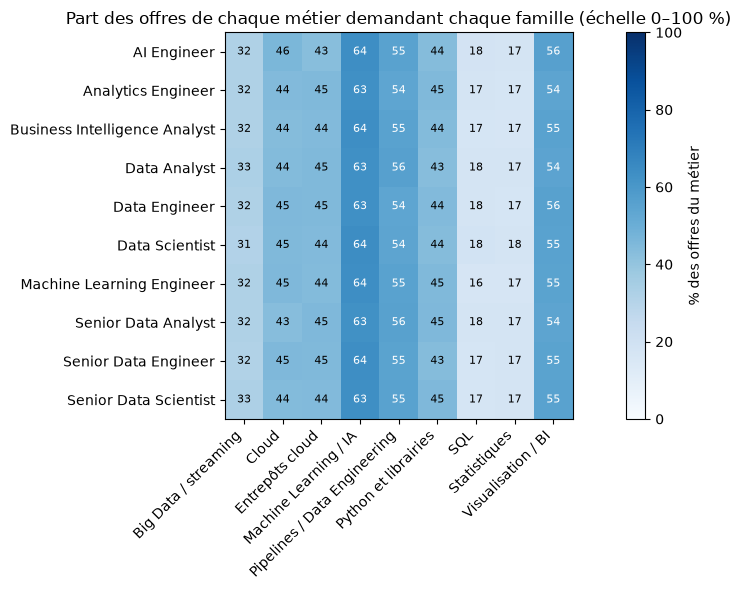

,min_pct,max_pct,ecart_points,V_cramer,p_value,significatif_apres_correction
famille,,,,,,
Cloud,"43,02","46,04","3,02","0,02","0,074000",False
SQL,"16,46","18,47","2,01","0,01","0,180000",False
Pipelines / Data Engineering,"53,58","55,87","2,29","0,01","0,189000",False
Python et librairies,"43,15","45,01","1,86","0,01","0,414000",False
Visualisation / BI,"54,09","55,94","1,85","0,01","0,594000",False
Entrepôts cloud,"42,95","45,31","2,36","0,01","0,596000",False
Big Data / streaming,"31,01","32,96","1,95","0,01","0,666000",False
Machine Learning / IA,"62,51","64,42","1,91","0,01","0,741000",False
Statistiques,"16,72","17,57","0,84","0,01","0,974000",False


Data Analyst vs AI Engineer (% des offres) :


job_title,Data Analyst,AI Engineer
skill,,
Big Data / streaming,"33,00","32,20"
Cloud,"44,00","46,00"
Entrepôts cloud,"44,60","42,90"
Machine Learning / IA,"63,00","63,70"
Pipelines / Data Engineering,"55,90","55,20"
Python et librairies,"43,20","43,60"
SQL,"17,80","18,10"
Statistiques,"17,30","17,40"
Visualisation / BI,"54,40","55,90"


In [12]:
familles_metier = skill_prevalence(offres, familles_offres, "job_title")
afficher(familles_metier.round(1))

fig, ax = plt.subplots(figsize=(11, 6))
image = ax.imshow(familles_metier.to_numpy(), cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(familles_metier.shape[1]), familles_metier.columns, rotation=45, ha="right")
ax.set_yticks(range(familles_metier.shape[0]), familles_metier.index)
for (ligne, colonne), valeur in np.ndenumerate(familles_metier.to_numpy()):
    ax.text(colonne, ligne, f"{valeur:.0f}", ha="center", va="center", fontsize=8,
            color="white" if valeur > 50 else "black")
fig.colorbar(image, ax=ax, label="% des offres du métier")
ax.set_title("Part des offres de chaque métier demandant chaque famille (échelle 0–100 %)")
plt.tight_layout()
plt.show()

lignes = []
for famille in familles_metier.columns:
    demande = offres.job_id.isin(familles_offres.loc[familles_offres.skill.eq(famille), "job_id"])
    tableau = pd.crosstab(offres.job_title, demande)
    chi2, p_value = chi2_contingency(tableau)[:2]
    lignes.append({"famille": famille,
                   "min_pct": familles_metier[famille].min(), "max_pct": familles_metier[famille].max(),
                   "ecart_points": familles_metier[famille].max() - familles_metier[famille].min(),
                   "V_cramer": np.sqrt(chi2 / tableau.to_numpy().sum()),
                   "p_value": p_value})
tests_familles = pd.DataFrame(lignes).set_index("famille").sort_values("p_value")
tests_familles["significatif_apres_correction"] = tests_familles.p_value < 0.05 / len(tests_familles)
afficher(tests_familles.round(3))

print("Data Analyst vs AI Engineer (% des offres) :")
afficher(familles_metier.loc[["Data Analyst", "AI Engineer"]].T.round(1))

Les profils par famille sont proches entre métiers dans ce fichier ; les écarts observés sont de quelques points.
Les tests et leurs tailles d'association doivent être lus ensemble. Un résultat non significatif ne démontre pas l'égalité des profils.
Ces données apportent peu d'éléments pour recommander des compétences propres à un métier avec confiance.

## 12. Comparaison Entry/Senior
Les pourcentages utilisent toutes les offres de chaque niveau, après dédoublonnage des liens.
La comparaison est réalisée tous métiers confondus et au sein de Data Analyst pour limiter les différences de composition.

,effectif_groupe
experience_level,
Entry,13 877
Lead,13 702
Mid,13 649
Senior,13 772


experience_level,Entry,Senior,ecart_Senior_Entry_points
skill,,,
Pandas,"16,77","17,61","0,84"
Power BI,"16,64","17,30","0,66"
Excel,"16,78","17,35","0,57"
Deep Learning,"16,84","17,38","0,54"
Python,"16,95","17,35","0,41"
SQL,"17,42","17,78","0,36"
PyTorch,"17,13","17,46","0,33"
GCP,"17,33","17,64","0,31"
Data Engineering,"17,20","17,49","0,29"


,effectif_Data_Analyst
experience_level,
Entry,1 401
Lead,1 364
Mid,1 389
Senior,1 352


experience_level,Entry,Senior,ecart_Senior_Entry_points
skill,,,
Redshift,"16,77","19,30","2,53"
ETL,"16,42","18,93","2,52"
TensorFlow,"16,13","18,49","2,36"
Pandas,"15,99","17,90","1,91"
Deep Learning,"17,06","18,86","1,80"
NumPy,"16,49","17,90","1,41"
Kafka,"17,56","18,79","1,23"
Tableau,"16,49","17,68","1,19"
Machine Learning,"16,56","17,68","1,12"


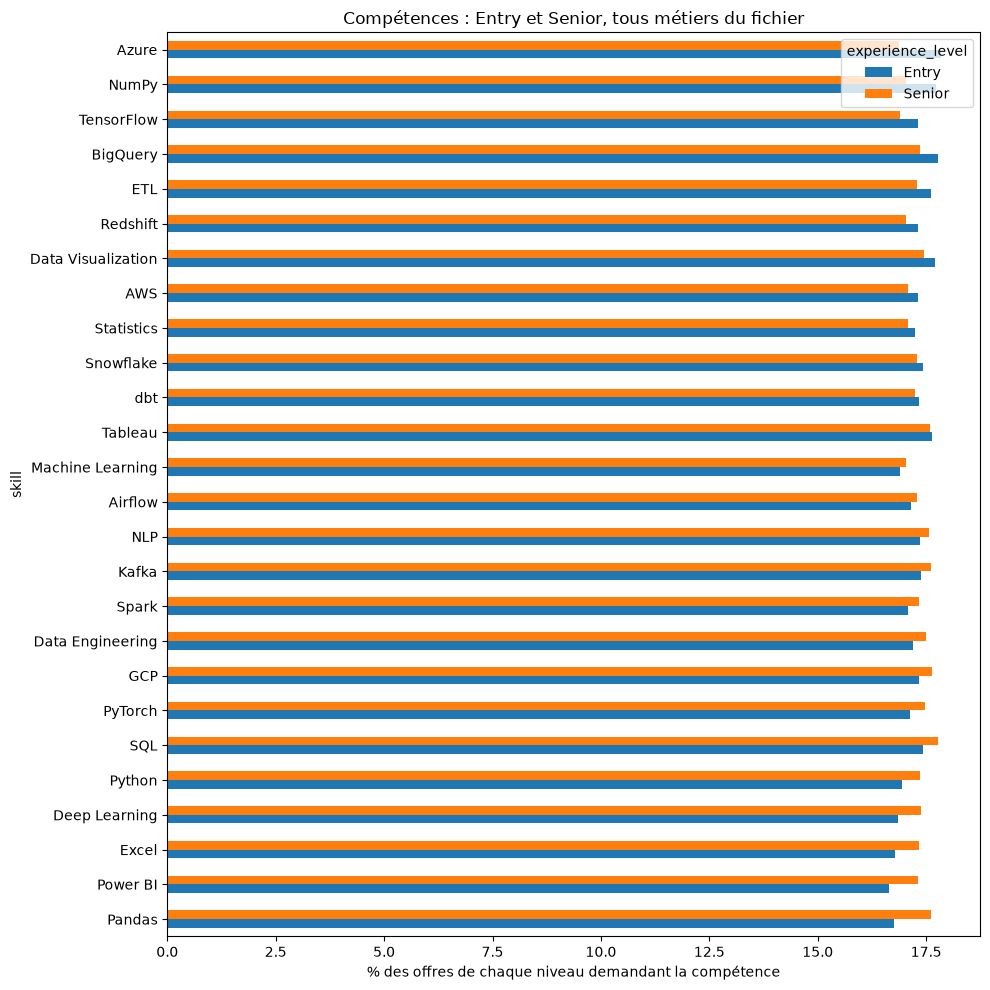

In [13]:
def comparer_entry_senior(selection):
    frequences = skill_prevalence(selection, competences_offres, "experience_level")
    comparaison = frequences.reindex(["Entry", "Senior"]).T
    comparaison["ecart_Senior_Entry_points"] = comparaison.Senior - comparaison.Entry
    return comparaison.sort_values("ecart_Senior_Entry_points", ascending=False)

afficher(offres.groupby("experience_level").size().rename("effectif_groupe"))
comparaison_competences = comparer_entry_senior(offres)
afficher(comparaison_competences.round(2))
offres_da = offres.loc[offres.job_title.eq("Data Analyst")]
afficher(offres_da.groupby("experience_level").size().rename("effectif_Data_Analyst"))
afficher(comparer_entry_senior(offres_da).round(2))
comparaison_competences[["Entry", "Senior"]].plot.barh(figsize=(10, 10))
plt.xlabel("% des offres de chaque niveau demandant la compétence")
plt.title("Compétences : Entry et Senior, tous métiers du fichier")
plt.tight_layout()
plt.show()

In [14]:
def tester_entry_senior(selection):
    """Chi² par compétence : part des offres Entry vs Senior qui la demandent."""
    niveaux = selection.loc[selection.experience_level.isin(["Entry", "Senior"])]
    liens = competences_offres[["job_id", "skill"]].drop_duplicates()
    lignes = []
    for competence in sorted(liens.skill.unique()):
        demande = niveaux.job_id.isin(liens.loc[liens.skill.eq(competence), "job_id"])
        table = pd.crosstab(niveaux.experience_level, demande)
        part = table[True] / table.sum(axis=1) * 100
        lignes.append({"competence": competence,
                       "ecart_Senior_Entry_points": part["Senior"] - part["Entry"],
                       "p_value": chi2_contingency(table)[1]})
    resultat = pd.DataFrame(lignes).set_index("competence").sort_values("p_value")
    # Correction de Bonferroni : on teste 26 compétences, donc le seuil devient 0,05 / 26
    resultat["significatif_apres_correction"] = resultat.p_value < 0.05 / len(resultat)
    return resultat

tests_da = tester_entry_senior(offres_da)
afficher(tests_da.head(8).round(4))
print("Compétences significatives (Data Analyst) :", tests_da.significatif_apres_correction.sum(), "/", len(tests_da))
print("Compétences significatives (tous métiers) :", tester_entry_senior(offres).significatif_apres_correction.sum(), "/", len(tests_da))

,ecart_Senior_Entry_points,p_value,significatif_apres_correction
competence,,,
Airflow,"-3,83","0,008500",False
ETL,"2,52","0,092500",False
BigQuery,"-2,50","0,093200",False
Redshift,"2,53","0,093400",False
TensorFlow,"2,36","0,112600",False
SQL,"-2,05","0,174600",False
Pandas,"1,91","0,198500",False
Deep Learning,"1,80","0,237200",False


Compétences significatives (Data Analyst) : 0 / 26


Compétences significatives (tous métiers) : 0 / 26


Les écarts maximaux observés sont d'environ 0,97 point tous métiers confondus et 3,83 points pour Data Analyst.
Aucun test ne franchit le seuil après correction de Bonferroni dans chacun des deux ensembles de 26 compétences.
Il s'agit d'une absence de différence détectée avec ce protocole, pas d'une preuve que les besoins n'évoluent pas avec l'expérience.

## 13. Analyse des pays

,nombre_offres,part_dataset_pct
country,,
France,4 398,"8,00"
Canada,4 314,"7,84"
Ireland,4 287,"7,79"
Australia,4 261,"7,75"
United Kingdom,4 249,"7,73"
Germany,4 232,"7,69"
Netherlands,4 218,"7,67"
Singapore,4 211,"7,66"
UAE,4 204,"7,64"


Couverture : 13 pays, 55,000 offres, soit 100 % du fichier.


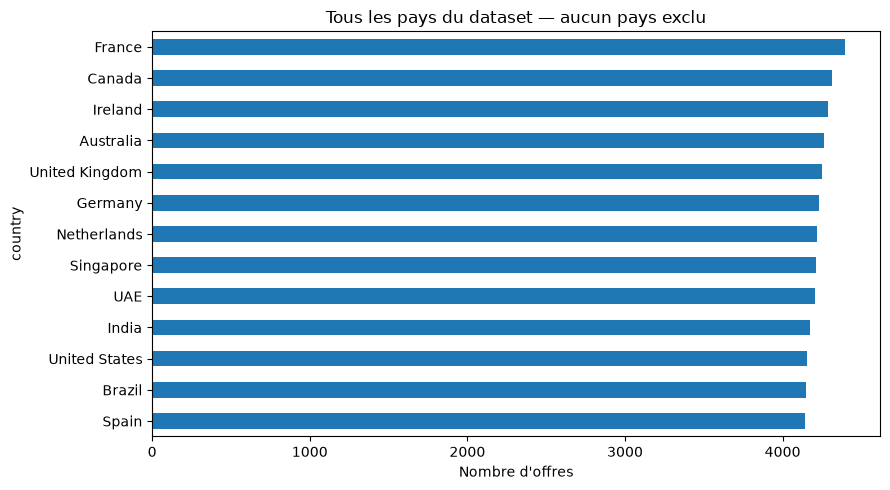

In [15]:
bilan_pays = offres.groupby("country").agg(nombre_offres=("job_id", "nunique"))
bilan_pays["part_dataset_pct"] = bilan_pays.nombre_offres / len(offres) * 100
bilan_pays = bilan_pays.sort_values("nombre_offres", ascending=False)
afficher(bilan_pays.round(2))
print(f"Couverture : {len(bilan_pays)} pays, {bilan_pays.nombre_offres.sum():,} offres, soit 100 % du fichier.")
bilan_pays.nombre_offres.sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Tous les pays du dataset — aucun pays exclu")
plt.xlabel("Nombre d'offres")
plt.tight_layout()
plt.show()

Les 13 pays sont tous conservés : aucun top 10 arbitraire. Les effectifs et leur part du fichier justifient la couverture.
Sans plan de collecte, ils ne mesurent pas le poids des marchés nationaux. Les comparaisons salariales en euros
n'intègrent ni pouvoir d'achat, fiscalité, temps de travail ni couverture nationale de la collecte.

## 14. Analyses statistiques et associations
Pearson et Spearman vont de **−1 à 1** ; le signe indique le sens de l'association.
Pearson mesure un lien linéaire, Spearman un lien monotone. Leurs valeurs proches ne démontrent pas la linéarité.
Le V de Cramér, η et η² vont de 0 à 1. Les seuils de lecture ne sont pas universels.

Le chi² teste une hypothèse d'indépendance sous ses conditions d'application. Une p-value élevée ne prouve pas cette indépendance.
Les tests par famille ou compétence utilisent Bonferroni ; les deux tests mode/métier et mode/expérience sont corrigés ensemble.
L'association ne démontre jamais une causalité. Les coefficients sont sans unité, même quand les variables salariales sont en euros.

Corrélation de Pearson


,salary_min_eur,salary_max_eur,salary_mid_eur,applicants_estimate
salary_min_eur,"1,00","0,97","0,99","-0,01"
salary_max_eur,"0,97","1,00","0,99","-0,01"
salary_mid_eur,"0,99","0,99","1,00","-0,01"
applicants_estimate,"-0,01","-0,01","-0,01","1,00"


Corrélation de Spearman


,salary_min_eur,salary_max_eur,salary_mid_eur,applicants_estimate
salary_min_eur,"1,00","0,97","0,99","-0,01"
salary_max_eur,"0,97","1,00","0,99","-0,01"
salary_mid_eur,"0,99","0,99","1,00","-0,01"
applicants_estimate,"-0,01","-0,01","-0,01","1,00"


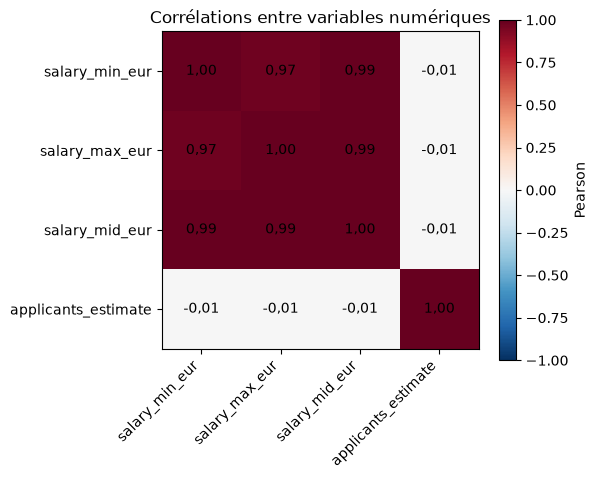

V de Cramér entre variables catégorielles


,job_title,experience_level,country,remote_option,employment_type
job_title,"1,00","0,01","0,01","0,02","0,01"
experience_level,"0,01","1,00","0,01","0,00","0,01"
country,"0,01","0,01","1,00","0,01","0,02"
remote_option,"0,02","0,00","0,01","1,00","0,01"
employment_type,"0,01","0,01","0,02","0,01","1,00"


Force du lien avec le salaire (valeur absolue)


,coefficient_sans_unite
job_title (η),"0,82"
country (η),"0,01"
compétence la plus liée (point-bisériel),"0,01"
applicants_estimate (Pearson),"0,01"
employment_type (η),"0,01"
remote_option (η),"0,01"
experience_level (η),"0,00"


Point-bisériel compétence × salaire, valeurs extrêmes :


,correlation
skill,
Snowflake,"-0,01"
Deep Learning,"-0,01"
Data Engineering,"-0,01"
Azure,"0,01"
Data Visualization,"0,01"
NLP,"0,01"


Plus forte corrélation entre deux compétences : 0.037


In [16]:
# 1. Numérique × numérique : Pearson et Spearman
variables_numeriques = ["salary_min_eur", "salary_max_eur", "salary_mid_eur", "applicants_estimate"]
for methode in ["pearson", "spearman"]:
    print(f"Corrélation de {methode.capitalize()}")
    afficher(offres[variables_numeriques].corr(method=methode).round(3))

fig, ax = plt.subplots(figsize=(6, 5))
matrice = offres[variables_numeriques].corr()
image = ax.imshow(matrice, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(variables_numeriques)), variables_numeriques, rotation=45, ha="right")
ax.set_yticks(range(len(variables_numeriques)), variables_numeriques)
for (ligne, colonne), valeur in np.ndenumerate(matrice.to_numpy()):
    ax.text(colonne, ligne, nombre_fr(valeur), ha="center", va="center")
fig.colorbar(image, ax=ax, label="Pearson")
ax.set_title("Corrélations entre variables numériques")
plt.tight_layout()
plt.show()

# 2. Associations catégorielles : fonction centralisée
variables_categorielles = ["job_title", "experience_level", "country", "remote_option", "employment_type"]
cramer = pd.DataFrame({a: {b: cramers_v(offres[a], offres[b]) for b in variables_categorielles}
                       for a in variables_categorielles})
print("V de Cramér entre variables catégorielles")
afficher(cramer.round(3))

# 3. Lien de chaque variable avec le salaire
lien_salaire = {f"{v} (η)": np.sqrt(eta_squared(offres[v], offres.salary_mid_eur)) for v in variables_categorielles}
lien_salaire["applicants_estimate (Pearson)"] = abs(offres.applicants_estimate.corr(offres.salary_mid_eur))

presence = (pd.crosstab(competences_offres.job_id, competences_offres.skill).clip(upper=1)
            .reindex(offres.job_id, fill_value=0))
point_biseriel = presence.corrwith(offres.set_index("job_id").salary_mid_eur)
lien_salaire["compétence la plus liée (point-bisériel)"] = point_biseriel.abs().max()

print("Force du lien avec le salaire (valeur absolue)")
afficher(pd.Series(lien_salaire, name="coefficient_sans_unite").sort_values(ascending=False).round(3).to_frame())
print("Point-bisériel compétence × salaire, valeurs extrêmes :")
afficher(point_biseriel.sort_values().iloc[[0, 1, 2, -3, -2, -1]].round(3).to_frame("correlation"))

# 4. Compétences entre elles (Pearson sur les variables 0/1, appelé coefficient phi)
phi = presence.corr().where(~np.eye(presence.shape[1], dtype=bool))
print(f"Plus forte corrélation entre deux compétences : {phi.abs().max().max():.3f}")

,variance_associee_pct
job_title,"67,18"
country,"0,02"
employment_type,"0,00"
remote_option,"0,00"
experience_level,"0,00"


,p_value,p_value_bonferroni,V_cramer,effectif_attendu_min
variable,,,,
experience_level,"0,989914","1,000000","0,00","4 513,35"
job_title,"0,044625","0,089249","0,02","1 768,44"


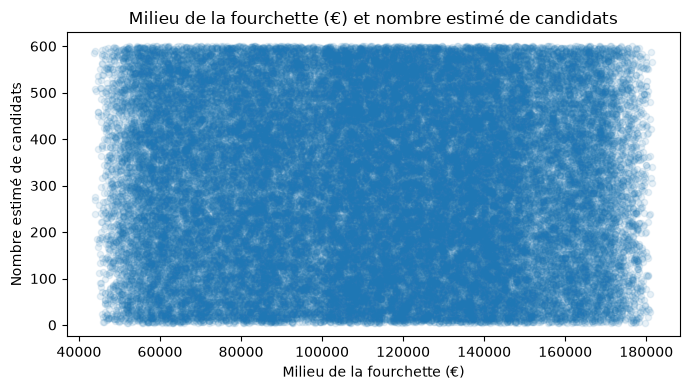

In [17]:
associations = pd.Series({v: eta_squared(offres[v], offres.salary_mid_eur) * 100
                          for v in variables_categorielles}, name="variance_associee_pct")
afficher(associations.sort_values(ascending=False))
tests_modes = []
for variable in ["experience_level", "job_title"]:
    chi2, p, dof, expected = chi2_contingency(pd.crosstab(offres[variable], offres.remote_option))
    tests_modes.append({"variable": variable, "p_value": p, "p_value_bonferroni": min(1, p * 2),
                        "V_cramer": cramers_v(offres[variable], offres.remote_option),
                        "effectif_attendu_min": expected.min()})
afficher(pd.DataFrame(tests_modes).set_index("variable"))
offres.plot.scatter(x="salary_mid_eur", y="applicants_estimate", alpha=0.1, figsize=(7, 4))
plt.title("Milieu de la fourchette (€) et nombre estimé de candidats")
plt.xlabel("Milieu de la fourchette (€)")
plt.ylabel("Nombre estimé de candidats")
plt.tight_layout()
plt.show()

Environ **67 % de la variance du milieu des fourchettes est associée aux différences de moyennes entre métiers**
(η² ≈ 0,672). Cela ne signifie pas que le métier cause 67 % du salaire.
Les associations avec l'expérience et le pays sont nettement plus faibles dans ce fichier.
Les V de Cramér entre variables différentes sont faibles ; la diagonale compare chaque variable à elle-même et ne s'interprète pas comme une découverte.

## 15. Limites du dataset
- Le milieu des bornes ne correspond pas à une rémunération effectivement versée.
- La période salariale, les détails de collecte et la représentativité ne sont pas établis par les fichiers.
- Les dates ne permettent pas une analyse chronologique fiable.
- Le taux USD/EUR est indicatif et fixe, sans correction du coût de la vie.
- Les intitulés et niveaux d'expérience sont deux informations distinctes, parfois difficiles à rapprocher.
- Les tests multiples et les faibles écarts limitent les conclusions ; un résultat non significatif n'est pas une preuve d'absence d'effet.
- Les profils uniformes ne permettent pas, seuls, de conclure à une fabrication artificielle des données.

## 16. Conclusion de l'EDA
Les contrôles du fichier ne détectent ni doublon d'offre ni incohérence de liaison ou de bornes salariales.
Les dix métiers et les treize pays disposent d'effectifs permettant des comparaisons descriptives, sans garantir leur représentativité.

Les différences salariales observées sont surtout associées au métier. Elles sont plus faibles selon l'expérience et le pays,
y compris lors des comparaisons complémentaires. Les familles de compétences améliorent la lisibilité,
mais les écarts selon le métier et l'expérience restent limités dans ces données.

Ces résultats motivent une comparaison prédictive simple : moyenne globale, moyenne par métier et Ridge,
avec métier, expérience et pays comme variables principales. Une expérience enrichie permet de vérifier l'apport d'autres variables.
La modélisation et ses métriques en **USD** se trouvent exclusivement dans `02_Machine_Learning.ipynb`.